# Task 3: Multi-Class Image Classification with a CNN
**Dataset:** MNIST handwritten digits (60,000 training and 10,000 test images, 28 x 28 pixels, 10 classes).
**Framework:** TensorFlow / Keras.

| Task requirement | Where it is done |
|---|---|
| Standard vision dataset (MNIST) | Step 2 |
| Multi-layer CNN with custom convolution, max-pooling and fully connected layers | Step 5 |
| Data augmentation to reduce overfitting | Steps 4 and 5 (also dropout and early stopping) |
| Graph of training and validation accuracy curves | Step 7 |

The 10,000 test images are used once, at the end (Step 8). A separate validation set is used during training.



## Step 1: Import the libraries

In [1]:
import numpy as np                                   # numpy: maths on arrays
import matplotlib.pyplot as plt                      # matplotlib: draws charts
import tensorflow as tf                              # TensorFlow: deep learning library
from tensorflow import keras                         # Keras: simple interface to build networks
from tensorflow.keras import layers                  # the building blocks (layers)
from sklearn.model_selection import train_test_split # splits the data
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report   # evaluation tools

keras.utils.set_random_seed(42)                      # fixed random seed for repeatable results
print("TensorFlow version:", tf.__version__)         # show the version
print("GPU found:", len(tf.config.list_physical_devices("GPU")) > 0)   # True if a GPU is active

TensorFlow version: 2.21.0
GPU found: False


## Step 2: Load MNIST

In [2]:
(x_train_full, y_train_full), (x_test, y_test) = keras.datasets.mnist.load_data()   # download and load MNIST
print("Training images:", x_train_full.shape)        # expected: (60000, 28, 28)
print("Test images    :", x_test.shape)              # expected: (10000, 28, 28)
print("Pixel range    :", x_train_full.min(), "to", x_train_full.max())   # 0 (black) to 255 (white)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training images: (60000, 28, 28)
Test images    : (10000, 28, 28)
Pixel range    : 0 to 255


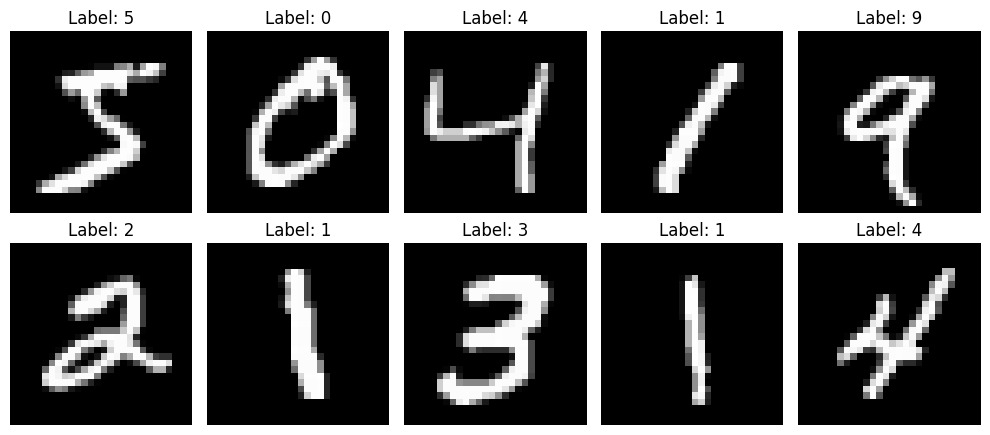

In [3]:
plt.figure(figsize=(10, 4.5))                        # figure size
for i in range(10):                                  # first 10 training images
    plt.subplot(2, 5, i + 1)                         # grid of 2 rows and 5 columns
    plt.imshow(x_train_full[i], cmap="gray")         # draw the image in gray
    plt.title("Label: " + str(y_train_full[i]))      # show the correct digit
    plt.axis("off")                                  # hide the axes
plt.tight_layout()                                   # tidy the layout
plt.show()                                           # draw the images

## Step 3: Prepare the images and make a validation set

In [4]:
x_train_full = x_train_full.astype("float32") / 255.0      # scale pixels from 0-255 to 0-1
x_test = x_test.astype("float32") / 255.0                  # same for the test images
x_train_full = np.expand_dims(x_train_full, -1)            # add a channel axis: (28, 28) becomes (28, 28, 1)
x_test = np.expand_dims(x_test, -1)                        # same for the test images
x_train, x_val, y_train, y_val = train_test_split(
    x_train_full, y_train_full,
    test_size=0.10,                                        # 10% of the training images become the validation set
    random_state=42,                                       # same split every time
    stratify=y_train_full)                                 # keep the same digit proportions
print("Train:", x_train.shape, "| Validation:", x_val.shape, "| Test:", x_test.shape)   # expected: 54000, 6000, 10000

Train: (54000, 28, 28, 1) | Validation: (6000, 28, 28, 1) | Test: (10000, 28, 28, 1)


## Step 4: Data augmentation
Each training image is randomly rotated, zoomed and shifted a little. The network sees many slightly different versions of every digit, which reduces overfitting. Augmentation is active only during training.

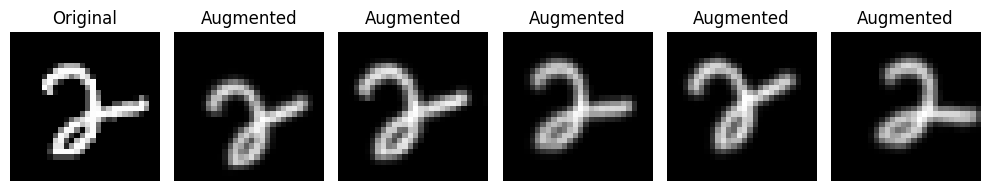

In [5]:
data_augmentation = keras.Sequential([
    layers.RandomRotation(0.05),                     # rotate by up to about 18 degrees
    layers.RandomZoom(0.1),                          # zoom in or out by up to 10%
    layers.RandomTranslation(0.1, 0.1)],             # shift up/down and left/right by up to 10%
    name="data_augmentation")
sample = np.repeat(x_train[:1], 5, axis=0)                       # 5 copies of the first training image
augmented = data_augmentation(sample, training=True)             # random changes applied to each copy
plt.figure(figsize=(10, 2.4))                                    # figure size
plt.subplot(1, 6, 1)                                             # first slot
plt.imshow(x_train[0].squeeze(), cmap="gray")                    # the original image
plt.title("Original")                                            # label
plt.axis("off")                                                  # hide the axes
for i in range(5):                                               # the 5 augmented copies
    plt.subplot(1, 6, i + 2)                                     # next slot
    plt.imshow(np.array(augmented[i]).squeeze(), cmap="gray")    # draw the augmented image
    plt.title("Augmented")                                       # label
    plt.axis("off")                                              # hide the axes
plt.tight_layout()                                               # tidy the layout
plt.show()                                                       # draw the images

## Step 5: Build the CNN

In [6]:
model = keras.Sequential([
    layers.Input(shape=(28, 28, 1)),                          # input: one 28 x 28 gray image
    data_augmentation,                                        # random changes (training only)
    layers.Conv2D(32, (3, 3), activation="relu"),             # convolution 1: 32 filters find simple edges
    layers.MaxPooling2D((2, 2)),                              # max-pooling 1: halves the image size
    layers.Conv2D(64, (3, 3), activation="relu"),             # convolution 2: 64 filters find shapes
    layers.MaxPooling2D((2, 2)),                              # max-pooling 2: halves the size again
    layers.Flatten(),                                         # turn the feature maps into one long vector
    layers.Dropout(0.3),                                      # randomly switch off 30% of values while training
    layers.Dense(128, activation="relu"),                     # fully connected layer with 128 neurons
    layers.Dense(10, activation="softmax")])                  # output layer: probability for each digit 0-9
model.compile(
    optimizer="adam",                                         # Adam optimizer
    loss="sparse_categorical_crossentropy",                   # loss for integer labels with 10 classes
    metrics=["accuracy"])                                     # report accuracy
model.summary()                                               # print the layers and the 225,034 parameters

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

## Step 6: Train the model

In [7]:
early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss",                  # watch the validation loss
    patience=3,                          # stop if it does not improve for 3 epochs
    restore_best_weights=True)           # go back to the best epoch
history = model.fit(
    x_train, y_train,                    # training images and labels
    validation_data=(x_val, y_val),      # validation images and labels
    epochs=15,                           # at most 15 passes over the training data
    batch_size=64,                       # 64 images per update
    callbacks=[early_stop])              # stop early when it stops improving

Epoch 1/15
844/844 ━━━━━━━━━━━━━━━━━━━━ 58s 65ms/step - accuracy: 0.8693 - loss: 0.4124 - val_accuracy: 0.9757 - val_loss: 0.0955
Epoch 2/15
844/844 ━━━━━━━━━━━━━━━━━━━━ 54s 64ms/step - accuracy: 0.9545 - loss: 0.1473 - val_accuracy: 0.9817 - val_loss: 0.0608
Epoch 3/15
844/844 ━━━━━━━━━━━━━━━━━━━━ 53s 63ms/step - accuracy: 0.9666 - loss: 0.1102 - val_accuracy: 0.9838 - val_loss: 0.0574
Epoch 4/15
844/844 ━━━━━━━━━━━━━━━━━━━━ 54s 64ms/step - accuracy: 0.9716 - loss: 0.0906 - val_accuracy: 0.9840 - val_loss: 0.0537
Epoch 5/15
844/844 ━━━━━━━━━━━━━━━━━━━━ 55s 65ms/step - accuracy: 0.9761 - loss: 0.0798 - val_accuracy: 0.9882 - val_loss: 0.0450
Epoch 6/15
844/844 ━━━━━━━━━━━━━━━━━━━━ 53s 63ms/step - accuracy: 0.9781 - loss: 0.0703 - val_accuracy: 0.9883 - val_loss: 0.0439
Epoch 7/15
844/844 ━━━━━━━━━━━━━━━━━━━━ 53s 63ms/step - accuracy: 0.9800 - loss: 0.0650 - val_accuracy: 0.9907 - val_loss: 0.0359
Epoch 8/15
844/844 ━━━━━━━━━━━━━━━━━━━━ 53s 63ms/step - accuracy: 0.9811 - loss: 0.0609 - 

## Step 7: Training and validation curves
Training accuracy can be lower than validation accuracy here, because augmentation and dropout make the training images harder.

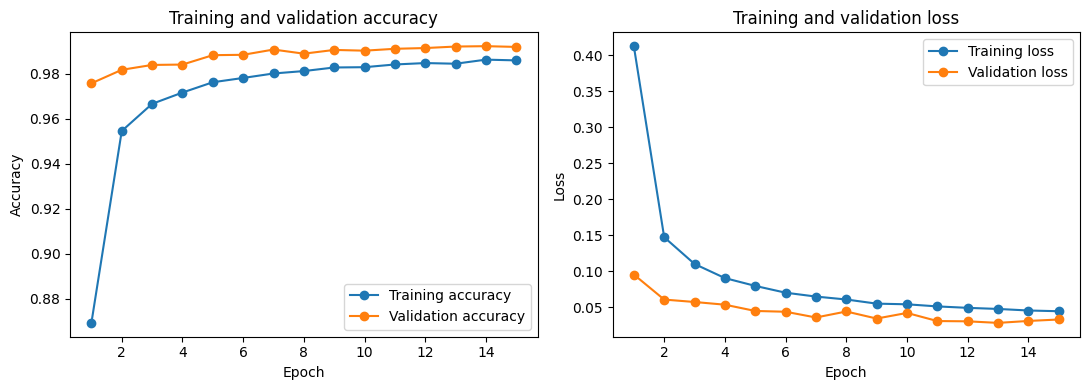

In [8]:
epochs_run = range(1, len(history.history["accuracy"]) + 1)         # epoch numbers 1, 2, 3, ...
plt.figure(figsize=(11, 4))                                         # figure size
plt.subplot(1, 2, 1)                                                # left chart: accuracy
plt.plot(epochs_run, history.history["accuracy"], marker="o", label="Training accuracy")        # training curve
plt.plot(epochs_run, history.history["val_accuracy"], marker="o", label="Validation accuracy")  # validation curve
plt.xlabel("Epoch")                                                 # x-axis label
plt.ylabel("Accuracy")                                              # y-axis label
plt.title("Training and validation accuracy")                       # title
plt.legend()                                                        # legend
plt.subplot(1, 2, 2)                                                # right chart: loss
plt.plot(epochs_run, history.history["loss"], marker="o", label="Training loss")                # training loss
plt.plot(epochs_run, history.history["val_loss"], marker="o", label="Validation loss")          # validation loss
plt.xlabel("Epoch")                                                 # x-axis label
plt.ylabel("Loss")                                                  # y-axis label
plt.title("Training and validation loss")                           # title
plt.legend()                                                        # legend
plt.tight_layout()                                                  # tidy the layout
plt.savefig("training_curves.png", dpi=150)                         # save the picture for the README
plt.show()                                                          # draw the charts

## Step 8: Final evaluation on the test images

In [9]:
test_loss, test_accuracy = model.evaluate(x_test, y_test, verbose=0)   # score on the 10,000 test images
print(f"Test accuracy: {test_accuracy:.4f}   Test loss: {test_loss:.4f}")   # print both numbers
probabilities = model.predict(x_test, verbose=0)                       # probabilities for each test image
y_pred = np.argmax(probabilities, axis=1)                              # the digit with the highest probability
wrong = int((y_pred != y_test).sum())                                  # number of wrong predictions
print("Wrong predictions:", wrong, "out of", len(y_test))              # how many mistakes

Test accuracy: 0.9942   Test loss: 0.0210
Wrong predictions: 58 out of 10000


              precision    recall  f1-score   support

           0     0.9980    0.9969    0.9974       980
           1     0.9965    0.9965    0.9965      1135
           2     0.9904    0.9971    0.9937      1032
           3     0.9950    0.9941    0.9946      1010
           4     0.9879    0.9990    0.9934       982
           5     0.9955    0.9944    0.9950       892
           6     0.9969    0.9927    0.9948       958
           7     0.9893    0.9932    0.9913      1028
           8     0.9949    0.9918    0.9933       974
           9     0.9980    0.9861    0.9920      1009

    accuracy                         0.9942     10000
   macro avg     0.9942    0.9942    0.9942     10000
weighted avg     0.9942    0.9942    0.9942     10000



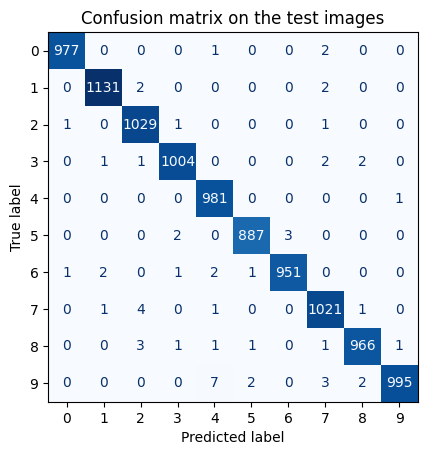

In [10]:
print(classification_report(y_test, y_pred, digits=4))                 # precision, recall and F1 for every digit
cm = confusion_matrix(y_test, y_pred)                                  # counts of true digit versus predicted digit
ConfusionMatrixDisplay(cm, display_labels=list(range(10))).plot(cmap="Blues", colorbar=False)   # draw the matrix
plt.title("Confusion matrix on the test images")                       # title
plt.show()                                                             # draw it

## Step 9: Look at some mistakes

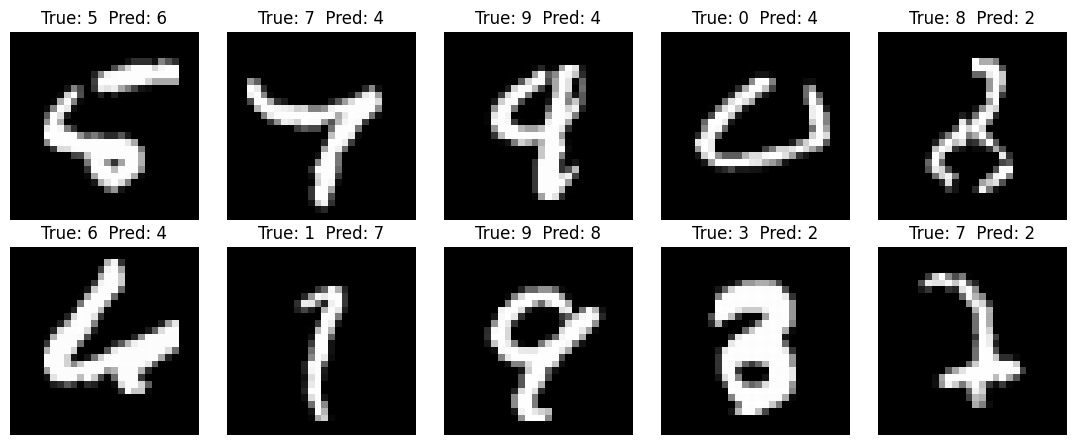

In [11]:
wrong_idx = np.where(y_pred != y_test)[0][:10]                         # positions of the first 10 mistakes
plt.figure(figsize=(11, 4.5))                                          # figure size
for k, i in enumerate(wrong_idx):                                      # loop over the mistakes
    plt.subplot(2, 5, k + 1)                                           # grid of 2 rows and 5 columns
    plt.imshow(x_test[i].squeeze(), cmap="gray")                       # draw the image
    plt.title(f"True: {y_test[i]}  Pred: {y_pred[i]}")                 # true digit and predicted digit
    plt.axis("off")                                                    # hide the axes
plt.tight_layout()                                                     # tidy the layout
plt.show()                                                             # draw the images

In [12]:
from google.colab import files                                         # Colab download tool
files.download("training_curves.png")                                  # download the curves picture for the GitHub README

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Conclusion
1. **Test accuracy:** the CNN reaches 99.42% accuracy on the 10,000 test images (test loss 0.0210). It makes 58 wrong predictions.
2. **Curves:** training and validation accuracy stay close together (training 98.59%, validation 99.18% in the last epoch), so there is no sign of overfitting. Training accuracy is a little lower than validation accuracy because augmentation and dropout make the training images harder. Early stopping did not trigger. All 15 epochs ran, and the validation loss was still near its lowest value (0.0285 at epoch 13, 0.0332 at epoch 15). More epochs might help a little.
3. **Mistakes:** every digit has precision and recall above 98.6%. Digit 9 has the most mistakes (14 of its 1,009 images, recall 98.61%). The most common confusion is a real 9 predicted as 4 (7 times). Other confusions are 7 as 2 (4 times), and 8 as 2, 9 as 7 and 5 as 6 (3 times each). These are digits that can look alike when written fast.
4. **Limits:** MNIST is a clean and easy dataset, so a high accuracy does not prove the model works on messy real images. I used one training run and one random seed, so the last decimals of the accuracy can change a little between runs.